# Real + Imaginary Combined MP-PCA Denoising

Gaussian noise가 추가된 multi-echo GRE complex 데이터를 Real과 Imaginary 성분으로 분리한 뒤, 두 성분을 채널 방향으로 결합하여 하나의 MP-PCA denoising을 수행한다.

6-echo 데이터의 경우 입력은 `[Real 6채널 | Imaginary 6채널]` 형태의 총 12채널 real-valued 데이터가 된다.

Real과 Imaginary 데이터에는 음수 값이 존재할 수 있으므로, DIPY의 `localpca.py`를 기반으로 non-negative clipping 부분을 제거한 `localpca_dn.py`의 `mppca()`를 사용한다.

Denoising 후 앞 6채널은 Real, 뒤 6채널은 Imaginary로 다시 분리하고 complex 데이터로 재결합하여 magnitude 영상을 비교한다.

In [2]:
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt
from pathlib import Path

from localpca_dn import mppca

### 환경설정

In [4]:
NOISE_LEVELS = [10, 30, 50]
PATCH_R = 2
N_ECHO = 6

NOISY_DIR = Path("./data/noisy_data")
OUT_DIR = Path("./data/denoised/real_imag_combined")

OUT_DIR.mkdir(parents=True, exist_ok=True)

### 1. Noise 데이터 불러오기

In [6]:
noisy_datasets = {}

for noise_level in NOISE_LEVELS:
    noisy_path = (
        NOISY_DIR /
        f"noisy_meas_gre_dir1_{noise_level}.mat"
    )

    noisy_data = sio.loadmat(
        noisy_path,
        simplify_cells=True
    )

    noisy_real = noisy_data["noisy_real"].astype(np.float32)
    noisy_imag = noisy_data["noisy_imag"].astype(np.float32)
    mask = noisy_data["mask_brain"].astype(bool)

    noisy_datasets[noise_level] = {
        "noisy_real": noisy_real,
        "noisy_imag": noisy_imag,
        "mask": mask,
        "metadata": noisy_data,
    }

    print(f"{noise_level}% noise 데이터 로드 완료")
    print("Real shape :", noisy_real.shape)
    print("Imag shape :", noisy_imag.shape)
    print("Mask shape :", mask.shape)

10% noise 데이터 로드 완료
Real shape : (256, 224, 176, 6)
Imag shape : (256, 224, 176, 6)
Mask shape : (256, 224, 176)
30% noise 데이터 로드 완료
Real shape : (256, 224, 176, 6)
Imag shape : (256, 224, 176, 6)
Mask shape : (256, 224, 176)
50% noise 데이터 로드 완료
Real shape : (256, 224, 176, 6)
Imag shape : (256, 224, 176, 6)
Mask shape : (256, 224, 176)


### 2. Real + Imaginary 12채널 결합

In [8]:
combined_data = {}

for noise_level in NOISE_LEVELS:
    noisy_real = noisy_datasets[noise_level]["noisy_real"]
    noisy_imag = noisy_datasets[noise_level]["noisy_imag"]

    # [R1 R2 ... R6 | I1 I2 ... I6]
    combined_input = np.concatenate(
        [noisy_real, noisy_imag],
        axis=-1
    ).astype(np.float32)

    combined_data[noise_level] = combined_input

    print(f"{noise_level}% Combined 데이터 생성 완료")
    print("Combined shape :", combined_input.shape)
    print("dtype :", combined_input.dtype)
    print("complex? :", np.iscomplexobj(combined_input))

10% Combined 데이터 생성 완료
Combined shape : (256, 224, 176, 12)
dtype : float32
complex? : False
30% Combined 데이터 생성 완료
Combined shape : (256, 224, 176, 12)
dtype : float32
complex? : False
50% Combined 데이터 생성 완료
Combined shape : (256, 224, 176, 12)
dtype : float32
complex? : False


### 3. Combined MP-PCA Denoising

In [10]:
deno_combined_data = {}

for noise_level in NOISE_LEVELS:
    combined_input = combined_data[noise_level]
    mask = noisy_datasets[noise_level]["mask"]

    print("\n" + "=" * 50)
    print(f"Noise level : {noise_level}%")
    print("Real + Imaginary Combined MP-PCA denoising")
    print("=" * 50)

    deno_combined = mppca(
        combined_input,
        mask=mask,
        patch_radius=PATCH_R
    )

    deno_combined_data[noise_level] = deno_combined

    print(f"{noise_level}% Combined denoising 완료")
    print("Output shape :", deno_combined.shape)


Noise level : 10%
Real + Imaginary Combined MP-PCA denoising


C:\Users\653wa\git\Graduation-Thesis\Research-Reimplementation\localpca_dn.py:376: RuntimeWarning: invalid value encountered in divide
  denoised_arr = thetax / theta


10% Combined denoising 완료
Output shape : (256, 224, 176, 12)

Noise level : 30%
Real + Imaginary Combined MP-PCA denoising
30% Combined denoising 완료
Output shape : (256, 224, 176, 12)

Noise level : 50%
Real + Imaginary Combined MP-PCA denoising
50% Combined denoising 완료
Output shape : (256, 224, 176, 12)


### 4. Real / Imaginary 분리 및 Complex 재결합

In [12]:
denoised_data = {}

for noise_level in NOISE_LEVELS:
    deno_combined = deno_combined_data[noise_level]

    # 앞 6채널 = Real, 뒤 6채널 = Imaginary
    deno_real = deno_combined[..., :N_ECHO]
    deno_imag = deno_combined[..., N_ECHO:]

    deno_complex = (
        deno_real.astype(np.complex64)
        + 1j * deno_imag.astype(np.complex64)
    )

    denoised_data[noise_level] = {
        "deno_combined": deno_combined,
        "deno_real": deno_real,
        "deno_imag": deno_imag,
        "deno_complex": deno_complex,
    }

    print(f"{noise_level}% complex 재결합 완료")
    print("Real shape    :", deno_real.shape)
    print("Imag shape    :", deno_imag.shape)
    print("Complex shape :", deno_complex.shape)

10% complex 재결합 완료
Real shape    : (256, 224, 176, 6)
Imag shape    : (256, 224, 176, 6)
Complex shape : (256, 224, 176, 6)
30% complex 재결합 완료
Real shape    : (256, 224, 176, 6)
Imag shape    : (256, 224, 176, 6)
Complex shape : (256, 224, 176, 6)
50% complex 재결합 완료
Real shape    : (256, 224, 176, 6)
Imag shape    : (256, 224, 176, 6)
Complex shape : (256, 224, 176, 6)


### 5. 결과 저장

In [14]:
for noise_level in NOISE_LEVELS:
    noisy_data = noisy_datasets[noise_level]["metadata"]

    deno_combined = denoised_data[noise_level]["deno_combined"]
    deno_real = denoised_data[noise_level]["deno_real"]
    deno_imag = denoised_data[noise_level]["deno_imag"]
    deno_complex = denoised_data[noise_level]["deno_complex"]

    output_path = (
        OUT_DIR /
        f"denoised_real_imag_combined_{noise_level}_r{PATCH_R}.mat"
    )

    save_data = {
        "deno_combined": deno_combined,
        "deno_real": deno_real,
        "deno_imag": deno_imag,
        "deno_complex": deno_complex,
        "mask_brain": noisy_data["mask_brain"],
        "noise_level": noise_level,
        "patch_radius": PATCH_R,
        "te_gre": noisy_data["te_gre"],
        "delta_TE": noisy_data["delta_TE"],
        "voxel_size_gre": noisy_data["voxel_size_gre"],
        "B0_dir": noisy_data["B0_dir"],
        "CF": noisy_data["CF"],
    }

    sio.savemat(
        output_path,
        save_data
    )

    print("저장 완료 →", output_path)

저장 완료 → data\denoised\real_imag_combined\denoised_real_imag_combined_10_r2.mat
저장 완료 → data\denoised\real_imag_combined\denoised_real_imag_combined_30_r2.mat
저장 완료 → data\denoised\real_imag_combined\denoised_real_imag_combined_50_r2.mat


### 6. 시각화

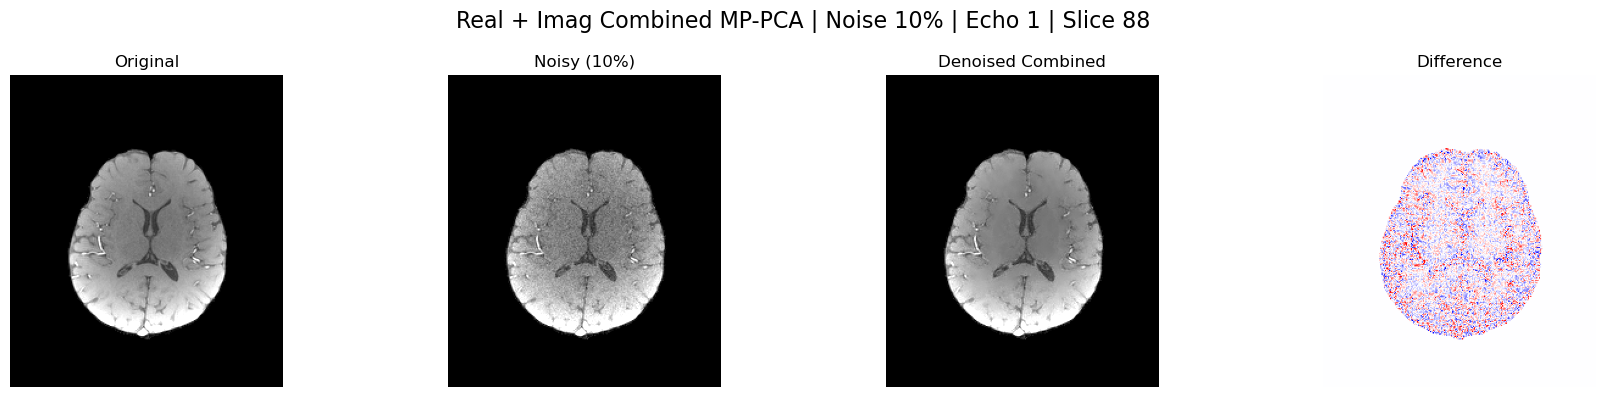

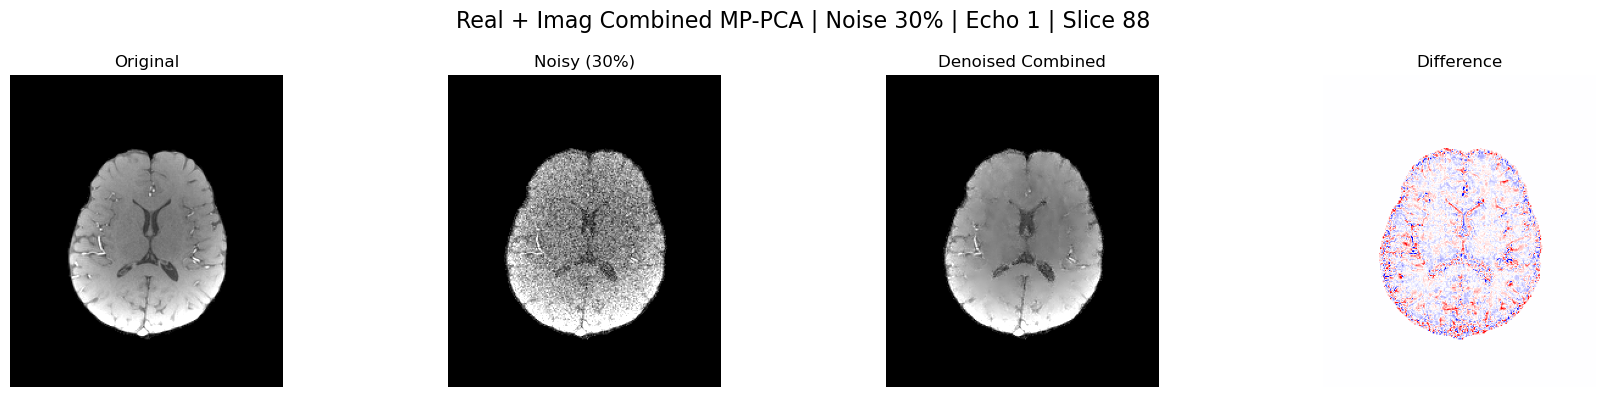

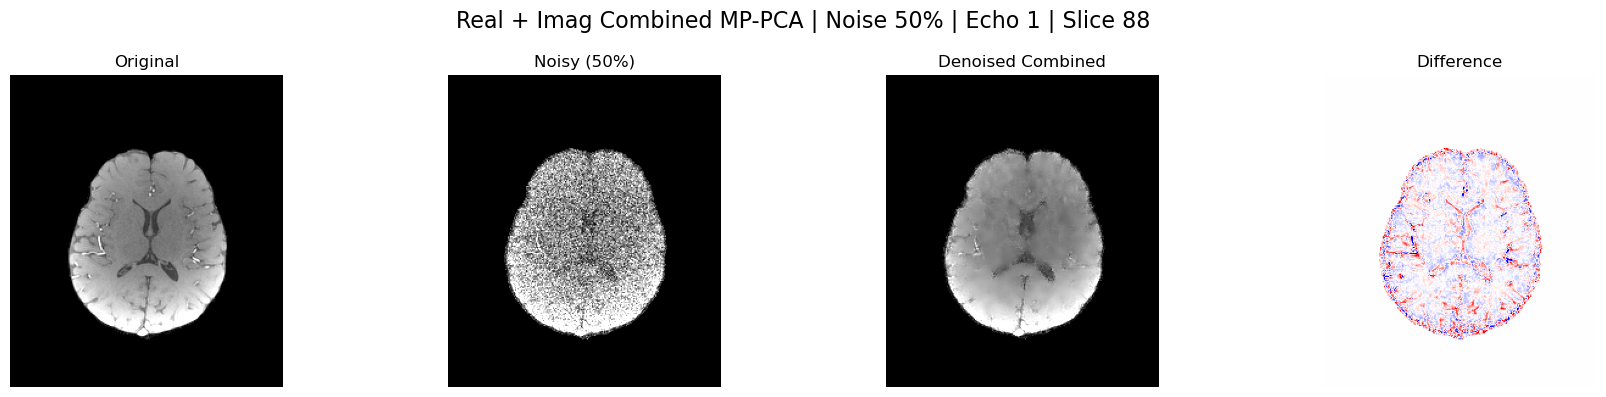

In [16]:
orig_data = sio.loadmat(
    "./data/meas_gre_dir1.mat",
    simplify_cells=True
)

orig_complex = orig_data["meas_gre"]
orig_mag = np.abs(orig_complex).astype(np.float32)

echo_idx = 0
slice_idx = 88

for noise_level in NOISE_LEVELS:
    noisy_real = noisy_datasets[noise_level]["noisy_real"]
    noisy_imag = noisy_datasets[noise_level]["noisy_imag"]
    mask = noisy_datasets[noise_level]["mask"]

    noisy_complex = (
        noisy_real.astype(np.complex64)
        + 1j * noisy_imag.astype(np.complex64)
    )

    deno_complex = denoised_data[noise_level]["deno_complex"]

    noisy_mag = np.abs(noisy_complex).astype(np.float32)
    deno_mag = np.abs(deno_complex).astype(np.float32)

    orig_2d = orig_mag[:, :, slice_idx, echo_idx]
    noisy_2d = noisy_mag[:, :, slice_idx, echo_idx]
    deno_2d = deno_mag[:, :, slice_idx, echo_idx]

    mask_2d = mask[:, :, slice_idx]

    diff_2d = deno_2d - orig_2d

    vmin, vmax = np.percentile(
        orig_mag[mask],
        (1, 99)
    )

    dv = np.percentile(
        np.abs(diff_2d[mask_2d]),
        99
    )

    fig, ax = plt.subplots(
        1,
        4,
        figsize=(18, 4)
    )

    ax[0].imshow(
        orig_2d,
        cmap="gray",
        vmin=vmin,
        vmax=vmax
    )
    ax[0].set_title("Original")
    ax[0].axis("off")

    ax[1].imshow(
        noisy_2d,
        cmap="gray",
        vmin=vmin,
        vmax=vmax
    )
    ax[1].set_title(f"Noisy ({noise_level}%)")
    ax[1].axis("off")

    ax[2].imshow(
        deno_2d,
        cmap="gray",
        vmin=vmin,
        vmax=vmax
    )
    ax[2].set_title("Denoised Combined")
    ax[2].axis("off")

    ax[3].imshow(
        diff_2d,
        cmap="bwr",
        vmin=-dv,
        vmax=dv
    )
    ax[3].set_title("Difference")
    ax[3].axis("off")

    fig.suptitle(
        f"Real + Imag Combined MP-PCA | Noise {noise_level}% | "
        f"Echo {echo_idx + 1} | Slice {slice_idx}",
        fontsize=16
    )

    plt.tight_layout()
    plt.show()